100%|██████████| 1.34G/1.34G [00:16<00:00, 86.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1

Folder structure:
/root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1/Cars_Body_Type/valid/Sedan -> 170 files, e.g. 03690_Acura-RL-Sedan-2012_jpg.rf.c28b6908ddafe19e260c869232a3fd18.jpg
/root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1/Cars_Body_Type/valid/Pick-Up -> 217 files, e.g. 06623_HUMMER-H3T-Crew-Cab-2010_jpg.rf.d4c67df76012dfcc1238a9fc08607a32.jpg
/root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1/Cars_Body_Type/valid/SUV -> 274 files, e.g. 06827_Infiniti-QX56-SUV-2011_jpg.rf.643a11ac8479322849910087d026aac4.jpg
/root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1/Cars_Body_Type/valid/VAN -> 162 files, e.g. 202105042165006_jpg.rf.310102849ae3470056707f68527a8965.jpg
/root/.cache/kagglehub/datasets/ademboukhris/cars-body-type-cropped/versions/1/Cars_Body_Type/valid/Cou

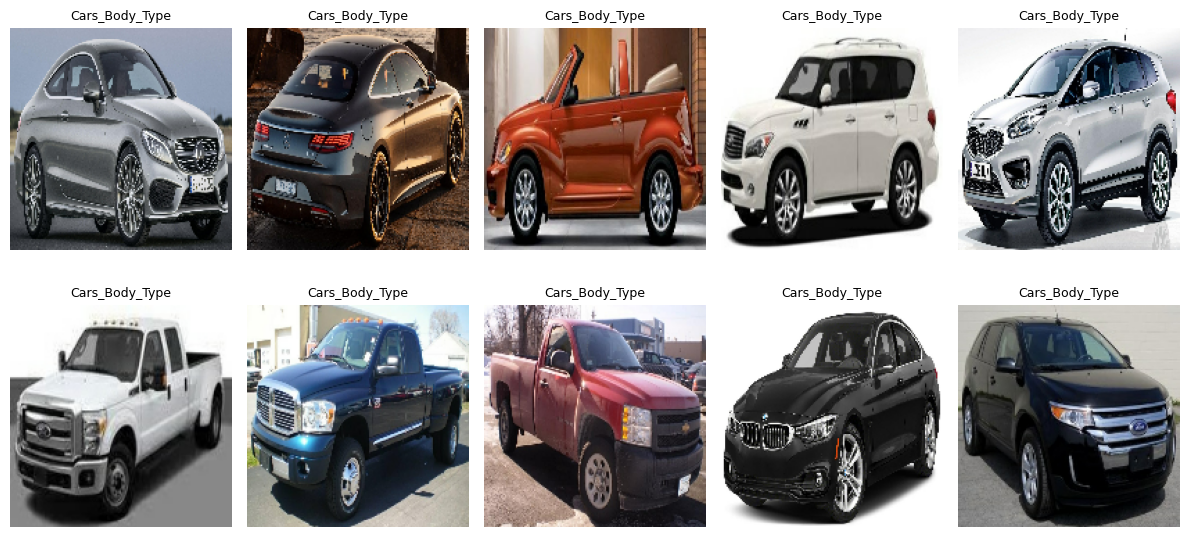

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "CarBodyTypeClassifier_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,593 (9.24 MB)

 Trainable params: 164,353 (642.00 KB)

 Non-trainable params: 2,258,240 (8.61 MB)


=== Phase 1: Training classifier head (frozen pretrained base) ===
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


131/189 ━━━━━━━━━━━━━━━━━━━━ 1:01 1s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00

In [ ]:
# ============================================
# Car Body Type Classification using Transfer Learning
# Pretrained backbone: MobileNetV2 (ImageNet weights)
#
# Dataset: ademboukhris/cars-body-type-cropped (Kaggle)
# Classes: Convertible, Coupe, Hatchback, Pick-Up, SUV, Sedan, VAN
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and inspect structure
# ----------------------------------------------------

path = kagglehub.dataset_download("ademboukhris/cars-body-type-cropped")
print("Path to dataset files:", path)

print("\nFolder structure:")
for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files, e.g.", files[0])

DATA_DIR = path

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# ----------------------------------------------------
# STEP 2: Load Dataset (auto 80/20 train/val split)
# ----------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="validation",
    seed=42
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Number of classes:", num_classes)
print("Classes:", class_names)

# ----------------------------------------------------
# STEP 3: Visualize Sample Images
# ----------------------------------------------------

plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(min(10, len(images))):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 4: Preprocess - Augment + MobileNetV2-specific preprocessing
# ----------------------------------------------------

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_prepped = prepare(train_ds, training=True)
val_ds_prepped = prepare(val_ds, training=False)

# ----------------------------------------------------
# STEP 5: Build model with PRETRAINED MobileNetV2 base
# ----------------------------------------------------

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs, name="CarBodyTypeClassifier_MobileNetV2")
model.summary()

# ----------------------------------------------------
# STEP 6: Phase 1 - Train classifier head only (base frozen)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

print("\n=== Phase 1: Training classifier head (frozen pretrained base) ===")
history1 = model.fit(
    train_ds_prepped,
    epochs=15,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 7: Phase 2 - Fine-tune top layers of the pretrained base
# ----------------------------------------------------

base_model.trainable = True

fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n=== Phase 2: Fine-tuning top layers of pretrained base ===")
history2 = model.fit(
    train_ds_prepped,
    epochs=10,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 8: Evaluate
# ----------------------------------------------------

val_loss, val_acc = model.evaluate(val_ds_prepped)
print(f"\nValidation Accuracy: {val_acc*100:.2f}%")

# ----------------------------------------------------
# STEP 9: Plot combined training history (both phases)
# ----------------------------------------------------

def merge_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(merge_history(history1, history2, 'accuracy'), label='Train Accuracy')
plt.plot(merge_history(history1, history2, 'val_accuracy'), label='Val Accuracy')
plt.axvline(x=len(history1.history['accuracy']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(merge_history(history1, history2, 'loss'), label='Train Loss')
plt.plot(merge_history(history1, history2, 'val_loss'), label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 10: Confusion Matrix & Classification Report
# ----------------------------------------------------

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([y.numpy() for x, y in val_ds_prepped], axis=0)
y_pred_probs = model.predict(val_ds_prepped)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

# ----------------------------------------------------
# STEP 11: Predict Body Type of a Single New Car Image
# ----------------------------------------------------

def predict_car_body_type(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    img_array = preprocess_input(img_array)
    prediction = model.predict(img_array)
    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100
    print(f"Predicted body type: {predicted_class} ({confidence:.2f}% confidence)")
    return predicted_class, confidence

# Example usage:
# predict_car_body_type("/path/to/some/car.jpg")

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('car_body_type_mobilenetv2.keras')
print("Model saved successfully!")